# Notebook 6 — Did the event increase firing?

**Summer course: data-analysis pitfalls**

One session, 2000 sorted units, 20 repeats of an event. We have spike times, unit
labels, and the event times. We want the population response to the event.

Units differ enormously in firing rate, from under 1 to over 100 spikes/s, so a
raw population average would be dominated by a handful of fast units. To account
for this, a colleague built each unit's PSTH, divided it by that unit's own
pre-event baseline, and averaged the normalized PSTHs across units.

> ### The claim
> *"The event drives a sustained ~9% increase in firing across the population
> (n = 2000 units, p = 9e-19). The baseline is flat and the increase begins in
> the first bin after the event."*

Run it and you'll see it: a clean flat baseline, then a step.

**The claim is false. Nothing in this dataset responds to the event.** Your job is
to work out how the figure came to look like that. `hints.md` has guiding
questions and `notebook6_solution.ipynb` has the answer.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import ttest_1samp

plt.rcParams['font.family']       = 'Arial'
plt.rcParams['font.sans-serif']   = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['pdf.fonttype']      = 42
plt.rcParams['ps.fonttype']       = 42


def band(ax, x, m, s, color, label=None):
    """Mean with a shaded +/- SEM band."""
    ax.fill_between(x, m - s, m + s, color=color, alpha=0.25, lw=0, zorder=2)
    ax.plot(x, m, '-', color=color, lw=1.8, zorder=3, label=label)


In [2]:
d = np.load('data/data.npz')
spike_times    = d['spike_times'].astype(float)    # (n_spikes,) s, ascending
spike_clusters = d['spike_clusters'].astype(int)   # (n_spikes,) unit index per spike
event_times    = d['event_times']                  # (n_events,) s
n_neurons      = int(d['n_neurons'])
duration       = float(d['recording_duration'])    # s
n_events       = len(event_times)
print(f'{n_neurons} units, {n_events} events, {len(spike_times):,} spikes, '
      f'{duration:.1f} s recording')

session_rate = np.bincount(spike_clusters, minlength=n_neurons) / duration
print(f'session-wide firing rate: median {np.median(session_rate):.2f}, '
      f'range {session_rate.min():.2f} to {session_rate.max():.0f} spikes/s')


2000 units, 20 events, 559,703 spikes, 52.1 s recording
session-wide firing rate: median 3.07, range 0.48 to 158 spikes/s


## Step 1 — Look at the raw data

Before any averaging, a raster of a few example units around the first five
events. Rows are trials, grouped by unit.


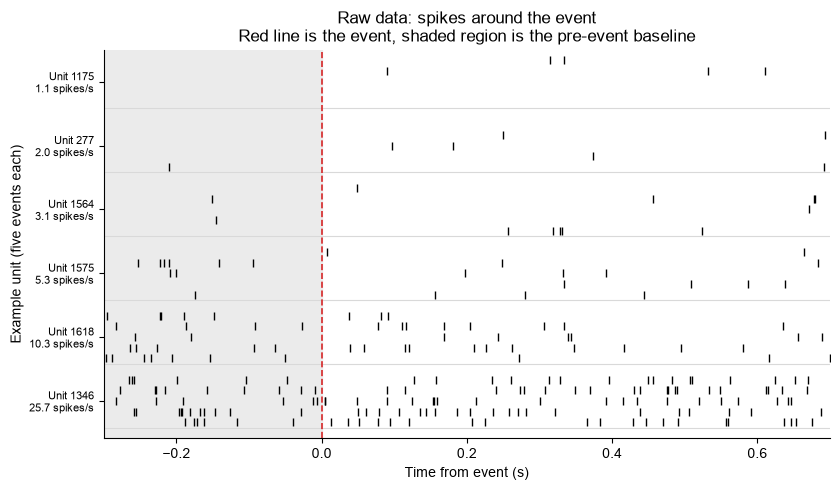

In [3]:
# Six example units spanning the rate range, five consecutive events each.
order    = np.argsort(session_rate)
ex_units = order[[int(f*(n_neurons-1)) for f in (0.10, 0.30, 0.50, 0.70, 0.88, 0.98)]]
ex_events = np.arange(5)
WIN_LOOK = (-0.30, 0.70)

fig, ax = plt.subplots(figsize=(8.5, 5.0))
row = 0
yticks, ylabels = [], []
for u in ex_units:
    st_u = spike_times[spike_clusters == u]
    rows_here = []
    for j in ex_events:
        rel = st_u - event_times[j]
        rel = rel[(rel >= WIN_LOOK[0]) & (rel < WIN_LOOK[1])]
        ax.plot(rel, np.full(rel.size, row), '|', color='k', ms=6, mew=1.0)
        rows_here.append(row)
        row += 1
    yticks.append(np.mean(rows_here))
    ylabels.append(f'Unit {u}\n{session_rate[u]:.1f} spikes/s')
    ax.axhline(row - 0.5, color='0.85', lw=0.8)
    row += 1

ax.axvspan(WIN_LOOK[0], 0.0, color='0.92', zorder=0)
ax.axvline(0.0, color='tab:red', ls='--', lw=1.2)
ax.set_yticks(yticks); ax.set_yticklabels(ylabels, fontsize=8)
ax.set_ylim(row - 0.5, -1.0)
ax.set_xlim(*WIN_LOOK)
ax.set_xlabel('Time from event (s)')
ax.set_ylabel('Example unit (five events each)')
ax.set_title('Raw data: spikes around the event\n'
             'Red line is the event, shaded region is the pre-event baseline')
plt.tight_layout(); plt.show()


## Step 2 — Build the PSTH

Count spikes in 50 ms bins from 300 ms before each event to 700 ms after, then
convert to a firing rate. The pre-event bins are the baseline.


In [4]:
WIN = (-0.30, 0.70)      # s relative to the event
BIN = 0.05               # s, PSTH bin width

def psth_counts(win, bin_w, trials=None):
    """Spike counts in bins relative to each event -> (units, trials, bins)."""
    edges  = np.arange(win[0], win[1] + bin_w / 2, bin_w)
    events = event_times if trials is None else event_times[trials]
    counts = np.zeros((n_neurons, len(events), len(edges) - 1))
    for j, t_ev in enumerate(events):
        rel = spike_times - t_ev                       # spike times re: this event
        sel = (rel >= win[0]) & (rel < win[1])
        b   = np.floor((rel[sel] - win[0]) / bin_w).astype(int)
        # np.add.at, NOT `counts[...] += 1`: fancy-index += drops repeated
        # indices, so a unit with two spikes in one bin on one trial would
        # be counted once. That silently undercounts high-rate units.
        np.add.at(counts[:, j, :], (spike_clusters[sel], b), 1)
    return counts, edges

counts, edges = psth_counts(WIN, BIN)
t_bin       = edges[:-1] + BIN / 2       # bin centers, s
rate        = counts.mean(1) / BIN       # (units, bins) firing rate, spikes/s
is_baseline = t_bin < 0                  # pre-event bins define the baseline
print(f'{rate.shape[1]} bins of {BIN*1000:.0f} ms: '
      f'{is_baseline.sum()} baseline, {(~is_baseline).sum()} post-event')


20 bins of 50 ms: 6 baseline, 14 post-event


That gives a units x time matrix. Plotting it shows why some kind of
normalization is tempting: the rate distribution is enormously wide, so a plain
average across units is really a report on the fastest few percent.


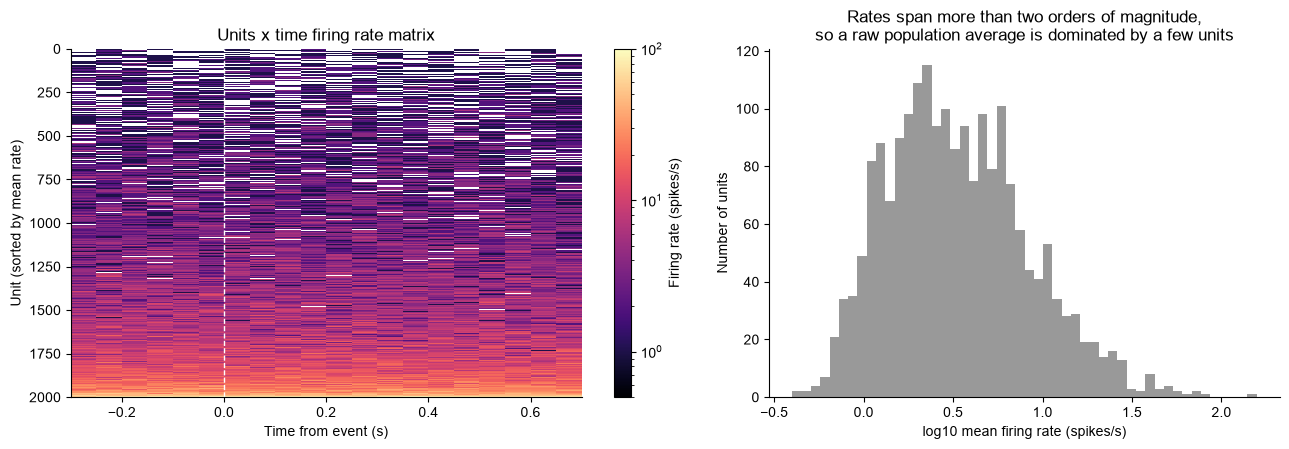

In [5]:
srt = np.argsort(rate.mean(1))           # sort units by their mean rate

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6),
                         gridspec_kw={'width_ratios': [1.25, 1]})

im = axes[0].imshow(rate[srt], aspect='auto', cmap='magma',
                    norm=LogNorm(vmin=0.5, vmax=100),
                    extent=[WIN[0], WIN[1], n_neurons, 0], interpolation='nearest')
axes[0].axvline(0.0, color='w', ls='--', lw=1.0)
axes[0].set_xlabel('Time from event (s)')
axes[0].set_ylabel('Unit (sorted by mean rate)')
axes[0].set_title('Units x time firing rate matrix')
cb = fig.colorbar(im, ax=axes[0]); cb.set_label('Firing rate (spikes/s)')

axes[1].hist(np.log10(rate.mean(1)), bins=50, color='0.6')
axes[1].set_xlabel('log10 mean firing rate (spikes/s)')
axes[1].set_ylabel('Number of units')
axes[1].set_title('Rates span more than two orders of magnitude,\n'
                  'so a raw population average is dominated by a few units')
plt.tight_layout(); plt.show()


## Step 3 — Normalize each unit to its own baseline, then average

Each unit's PSTH is divided by that unit's mean baseline rate, so every unit
contributes on a common scale where 1 means "at baseline". Then average across
units and plot mean with a shaded SEM band.


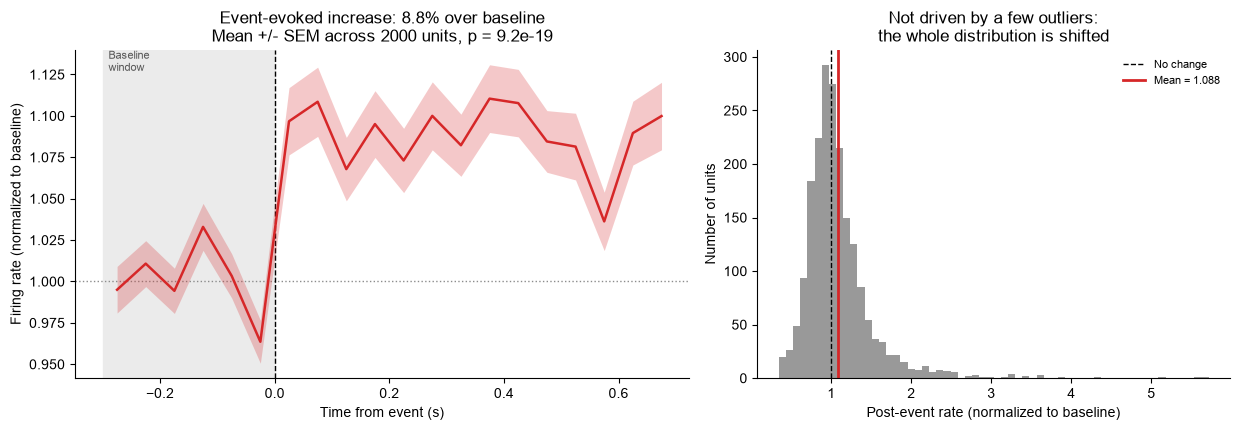

mean normalized rate after the event : 1.0881  (+8.8%)
mean normalized rate in baseline     : 1.0000
units above 1 after the event        : 49.9%
t-test vs 1 across units             : t = 8.93, p = 9.19e-19


In [6]:
baseline = rate[:, is_baseline].mean(1)          # (units,) baseline rate, spikes/s
norm     = rate / baseline[:, None]              # each unit relative to itself

mean_norm = norm.mean(0)
sem_norm  = norm.std(0, ddof=1) / np.sqrt(n_neurons)

# One number per unit: its mean normalized rate after the event
post_per_unit = norm[:, ~is_baseline].mean(1)
t_stat, p_val = ttest_1samp(post_per_unit, 1.0)
pct           = (post_per_unit.mean() - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4),
                         gridspec_kw={'width_ratios': [1.3, 1]})

ax = axes[0]
ax.axvspan(WIN[0], 0.0, color='0.92', zorder=0)
ax.axhline(1.0, color='0.55', ls=':', lw=1.0, zorder=1)
ax.axvline(0.0, color='k', ls='--', lw=1.0, zorder=1)
band(ax, t_bin, mean_norm, sem_norm, 'tab:red')
ax.text(WIN[0] + 0.01, ax.get_ylim()[1], 'Baseline\nwindow', va='top',
        ha='left', fontsize=8, color='0.35')
ax.set_xlabel('Time from event (s)')
ax.set_ylabel('Firing rate (normalized to baseline)')
ax.set_title(f'Event-evoked increase: {pct:.1f}% over baseline\n'
             f'Mean +/- SEM across {n_neurons} units, p = {p_val:.1e}')

ax = axes[1]
ax.hist(post_per_unit, bins=60, color='0.6')
ax.axvline(1.0, color='k', ls='--', lw=1.0, label='No change')
ax.axvline(post_per_unit.mean(), color='tab:red', lw=2,
           label=f'Mean = {post_per_unit.mean():.3f}')
ax.set_xlabel('Post-event rate (normalized to baseline)')
ax.set_ylabel('Number of units')
ax.set_title('Not driven by a few outliers:\nthe whole distribution is shifted')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'mean normalized rate after the event : {post_per_unit.mean():.4f}'
      f'  ({pct:+.1f}%)')
print(f'mean normalized rate in baseline     : {norm[:, is_baseline].mean():.4f}')
print(f'units above 1 after the event        : {np.mean(post_per_unit > 1)*100:.1f}%')
print(f't-test vs 1 across units             : t = {t_stat:.2f}, p = {p_val:.2e}')


A sustained ~9% increase, onset in the very first bin after the event, an
immaculate flat baseline, and p = 9e-19 across 2000 units. And it is not an
outlier effect: the whole per-unit distribution is shifted, with a clear majority
of units above 1.

Every single unit in this dataset fires at a constant rate for the whole
recording. **How did this figure happen?**
